# ORIE 5530 Project, Part I: Citi Bike stations as Markov chains

Stations: W 21 St & 6 Ave (office), Ave A & E 14 St (residential), 7 Ave & Central Park South (leisure).
Blocks: weekday mornings 7-10am and evenings 4-7pm. Step: 5 minutes. Transitions: replay the rides of each step in time order.

Input: `data/trips_clean.parquet` made by clean_data.py.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs/matrices", exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11})

In [2]:
# docks from Citi Bike's live station feed (station_information.json), read in November 2026
STATIONS = {
    "6140.05": {"name": "W 21 St", "docks": 74, "color": "#2a78d6"},
    "5779.11": {"name": "Ave A", "docks": 41, "color": "#eb6834"},
    "6912.01": {"name": "7 Ave & CPS", "docks": 81, "color": "#1baf7a"},
}
BLOCKS = {"Morning": (7, 10), "Evening": (16, 19)}
STEP = "5min"
STEPS_PER_BLOCK = 36

## 1. Load the rides and turn them into events

In [3]:
cols = ["started_at", "ended_at", "start_station_id", "end_station_id"]
trips = pd.read_parquet("data/trips_clean.parquet", columns=cols)
print(len(trips), "rides")

5240216 rides


In [4]:
# a ride is a departure (-1) at its start station and an arrival (+1) at its end station
departures = pd.DataFrame({"station": trips.start_station_id, "time": trips.started_at, "event": -1})
arrivals = pd.DataFrame({"station": trips.end_station_id, "time": trips.ended_at, "event": 1})
events = pd.concat([departures, arrivals], ignore_index=True).dropna(subset=["station"])

# some stations have a small extra dock with the same ID plus "_", we count it as the same station
events["station"] = events.station.astype(str).str.rstrip("_")

# keep August weekdays only, each event counted at its own timestamp
is_august = events.time.dt.month == 8
is_weekday = events.time.dt.dayofweek < 5
events = events[is_august & is_weekday].sort_values("time", kind="stable")

weekdays = pd.date_range("2026-08-01", "2026-08-31")
weekdays = weekdays[weekdays.dayofweek < 5]
print(len(weekdays), "weekdays,", len(events), "events")

21 weekdays, 6971216 events


## 2. Event sequences of each step

For every step of every weekday we keep the list of events in time order, e.g. [+1, +1, -1].
Steps with no rides give an empty list.

In [5]:
def get_sequences(station, block, step=STEP):
    start_h, end_h = BLOCKS[block]
    e = events[(events.station == station) & (events.time.dt.hour >= start_h) & (events.time.dt.hour < end_h)]
    e = e.assign(step=e.time.dt.floor(step))
    by_step = e.groupby("step").event.apply(list)

    step_length = pd.Timedelta(step)
    n_steps = int(pd.Timedelta(hours=end_h - start_h) / step_length)
    all_steps = [day + pd.Timedelta(hours=start_h) + k * step_length for day in weekdays for k in range(n_steps)]
    return [by_step.get(s, []) for s in all_steps], n_steps

In [6]:
seqs = {}
for sid in STATIONS:
    for block in BLOCKS:
        seqs[(sid, block)], _ = get_sequences(sid, block)

print({f"{STATIONS[s]['name']} {b}": len(v) for (s, b), v in seqs.items()})

{'W 21 St Morning': 756, 'W 21 St Evening': 756, 'Ave A Morning': 756, 'Ave A Evening': 756, '7 Ave & CPS Morning': 756, '7 Ave & CPS Evening': 756}


## 3. Transition matrices

Replay rule: start from i bikes and apply the events one at a time, never below 0 or above C.
Each row uses all 756 observed steps: P(i, j) = share of steps that take i bikes to j bikes.

In [7]:
def replay_matrix(sequences, C):
    P = np.zeros((C + 1, C + 1))
    start = np.arange(C + 1)
    for seq in sequences:
        bikes = start.copy()  # replay this step from every starting state at once
        for e in seq:
            bikes = np.clip(bikes + e, 0, C)
        P[start, bikes] += 1
    return P / len(sequences)

def net_change_matrix(sequences, C):
    # simpler rule for comparison: add arrivals minus departures, then cut at 0 and C
    P = np.zeros((C + 1, C + 1))
    start = np.arange(C + 1)
    for seq in sequences:
        end = np.clip(start + sum(seq), 0, C)
        P[start, end] += 1
    return P / len(sequences)

def stationary(P):
    eigvals, eigvecs = np.linalg.eig(P.T)
    pi = np.real(eigvecs[:, np.argmin(np.abs(eigvals - 1))])
    pi = np.clip(pi / pi.sum(), 0, None)
    return pi / pi.sum()

In [8]:
P_all = {}
pi_all = {}
for (sid, block), s in seqs.items():
    P_all[(sid, block)] = replay_matrix(s, STATIONS[sid]["docks"])
    pi_all[(sid, block)] = stationary(P_all[(sid, block)])

## 4. Choosing the step (report Table 5)

In [9]:
rows = []
for step in ["15s", "5min", "10min"]:
    for sid in STATIONS:
        for block in BLOCKS:
            s, n_steps = get_sequences(sid, block, step)
            net = np.array([sum(x) for x in s])
            both = np.mean([(1 in x) and (-1 in x) for x in s])
            by_day = net.reshape(len(weekdays), n_steps)
            lag1 = np.corrcoef(by_day[:, :-1].ravel(), by_day[:, 1:].ravel())[0, 1]
            rows.append({"step": step, "station": STATIONS[sid]["name"], "block": block,
                         "share net 0": (net == 0).mean(), "sd net": net.std(),
                         "share arrivals and departures": both, "lag-1 corr": lag1, "steps": len(s)})
step_table = pd.DataFrame(rows)
step_table.round(3)

,step,station,block,share net 0,sd net,share arrivals and departures,lag-1 corr,steps
0,15s,W 21 St,Morning,0.739,0.597,0.025,-0.010,15120
1,15s,W 21 St,Evening,0.671,0.687,0.041,0.009,15120
2,15s,Ave A,Morning,0.866,0.395,0.005,0.012,15120
3,15s,Ave A,Evening,0.778,0.534,0.019,-0.011,15120
4,15s,7 Ave & CPS,Morning,0.837,0.455,0.009,0.037,15120
5,15s,7 Ave & CPS,Evening,0.742,0.616,0.023,0.063,15120
6,5min,W 21 St,Morning,0.188,2.676,0.853,0.117,756
7,5min,W 21 St,Evening,0.134,3.172,0.919,0.051,756
8,5min,Ave A,Morning,0.263,1.865,0.541,0.044,756
9,5min,Ave A,Evening,0.192,2.442,0.815,-0.046,756


## 5. Rule and step: long-run share at the edge each chain moves towards (report Table 6)

In [10]:
EDGE = {"Morning": {"6140.05": "full", "5779.11": "empty", "6912.01": "full"},
        "Evening": {"6140.05": "empty", "5779.11": "full", "6912.01": "empty"}}

rows = []
for step, rule in [("15s", "observed order"), ("5min", "net change"), ("5min", "observed order"), ("10min", "observed order")]:
    row = {"step and rule": f"{step}, {rule}"}
    for sid in STATIONS:
        C = STATIONS[sid]["docks"]
        for block in BLOCKS:
            s, _ = get_sequences(sid, block, step)
            P = replay_matrix(s, C) if rule == "observed order" else net_change_matrix(s, C)
            pi = stationary(P)
            edge = EDGE[block][sid]
            row[f"{STATIONS[sid]['name']} {block} ({edge})"] = pi[C] if edge == "full" else pi[0]
    rows.append(row)
rule_table = pd.DataFrame(rows).set_index("step and rule")
rule_table.round(3)

,W 21 St Morning (full),W 21 St Evening (empty),Ave A Morning (empty),Ave A Evening (full),7 Ave & CPS Morning (full),7 Ave & CPS Evening (empty)
step and rule,,,,,,
"15s, observed order",0.320,0.211,0.283,0.184,0.242,0.173
"5min, net change",0.612,0.455,0.409,0.348,0.356,0.288
"5min, observed order",0.346,0.206,0.289,0.176,0.210,0.155
"10min, observed order",0.378,0.207,0.282,0.164,0.207,0.132


## 6. Checks of the assumptions (report Table 7)

- Same distribution in the three hours of a block: Kruskal-Wallis test on the net change per step.
- Independent steps: real sd of the block total across the 21 days vs the sd implied by independent steps.

In [11]:
rows = []
for (sid, block), s in seqs.items():
    net = np.array([sum(x) for x in s]).reshape(len(weekdays), STEPS_PER_BLOCK)
    hours = [net[:, 12 * k:12 * (k + 1)].ravel() for k in range(3)]
    p_value = stats.kruskal(*hours).pvalue

    block_total = net.sum(axis=1)
    sd_real = block_total.std()
    sd_independent = np.sqrt(net.var(axis=0).sum())  # variance of each step across days, so the trend within the block is not counted

    rows.append({"station": STATIONS[sid]["name"], "block": block,
                 "1st hour": hours[0].mean(), "2nd hour": hours[1].mean(), "3rd hour": hours[2].mean(),
                 "p-value": p_value, "sd real": sd_real, "sd independent": sd_independent,
                 "mean block total": block_total.mean()})
checks = pd.DataFrame(rows)
checks.round(3)

,station,block,1st hour,2nd hour,3rd hour,p-value,sd real,sd independent,mean block total
0,W 21 St,Morning,0.623,1.861,1.480,0.000,11.291,14.992,47.571
1,W 21 St,Evening,-0.619,-1.440,-1.250,0.003,13.565,18.537,-39.714
2,Ave A,Morning,-0.476,-0.556,-0.476,0.813,8.440,10.726,-18.095
3,Ave A,Evening,0.341,0.897,0.472,0.046,10.386,14.221,20.524
4,7 Ave & CPS,Morning,0.167,0.706,0.786,0.019,20.248,13.480,19.905
5,7 Ave & CPS,Evening,-0.389,-0.484,-1.155,0.038,20.287,20.221,-24.333


## 7. Summary of the matrices (report Table 8)

Away from the edges every row is the same distribution shifted, so the middle row plus the two corners describe each matrix.

In [12]:
rows = []
for (sid, block), P in P_all.items():
    C = STATIONS[sid]["docks"]
    mid = C // 2
    change = np.arange(C + 1) - mid
    row_mid = P[mid]
    mean = (row_mid * change).sum()
    sd = np.sqrt((row_mid * (change - mean) ** 2).sum())
    rows.append({"station": STATIONS[sid]["name"], "block": block, "mean": mean, "sd": sd,
                 "up": row_mid[change > 0].sum(), "same": row_mid[mid], "down": row_mid[change < 0].sum(),
                 "P(0,0)": P[0, 0], "P(C,C)": P[C, C]})
matrix_summary = pd.DataFrame(rows)
matrix_summary.round(3)

,station,block,mean,sd,up,same,down,"P(0,0)","P(C,C)"
0,W 21 St,Morning,1.321,2.676,0.587,0.188,0.225,0.216,0.505
1,W 21 St,Evening,-1.103,3.172,0.299,0.134,0.567,0.373,0.229
2,Ave A,Morning,-0.503,1.865,0.278,0.263,0.459,0.566,0.372
3,Ave A,Evening,0.570,2.442,0.496,0.192,0.312,0.296,0.402
4,7 Ave & CPS,Morning,0.553,2.383,0.466,0.231,0.303,0.366,0.481
5,7 Ave & CPS,Evening,-0.676,3.475,0.336,0.177,0.487,0.430,0.303


In [13]:
# full matrices for the appendix, row i and column j give P(i, j)
for (sid, block), P in P_all.items():
    name = STATIONS[sid]["name"].replace(" ", "").replace("&", "")
    pd.DataFrame(P).to_csv(f"outputs/matrices/P_{name}_{block}.csv")
print(sorted(os.listdir("outputs/matrices")))

['P_7AveCPS_Evening.csv', 'P_7AveCPS_Morning.csv', 'P_AveA_Evening.csv', 'P_AveA_Morning.csv', 'P_W21St_Evening.csv', 'P_W21St_Morning.csv']


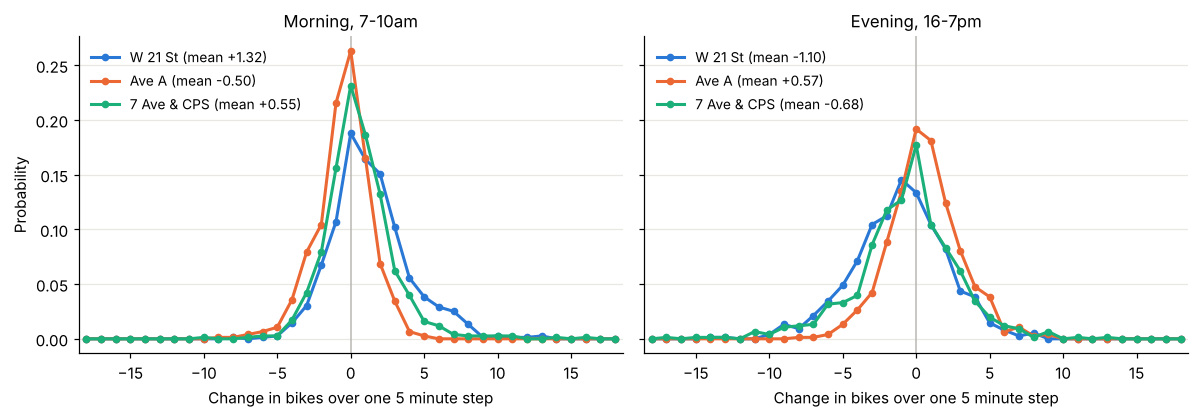

In [14]:
# Figure 3: middle row of each matrix
changes = np.arange(-18, 19)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, block in zip(axes, BLOCKS):
    ax.axvline(0, color="#b9b8b3", lw=1)
    for sid, st in STATIONS.items():
        C = st["docks"]
        mid = C // 2
        row_mid = np.array([P_all[(sid, block)][mid, mid + d] if 0 <= mid + d <= C else 0 for d in changes])
        ax.plot(changes, row_mid, color=st["color"], lw=2, marker="o", ms=4,
                label=f"{st['name']} (mean {(changes * row_mid).sum():+.2f})")
    start_h, end_h = BLOCKS[block]
    ax.set_title(f"{block}, {start_h}-{end_h % 12 or 12}{'am' if end_h < 12 else 'pm'}")
    ax.set_xlabel("Change in bikes over one 5 minute step")
    ax.set_xticks(range(-15, 16, 5))
    ax.set_xlim(-18.5, 18.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e8e7e3")
    ax.legend(frameon=False, loc="upper left", fontsize=9)
axes[0].set_ylabel("Probability")
fig.tight_layout()
fig.savefig("figures/p1_matrix_rows.png", dpi=250, bbox_inches="tight")

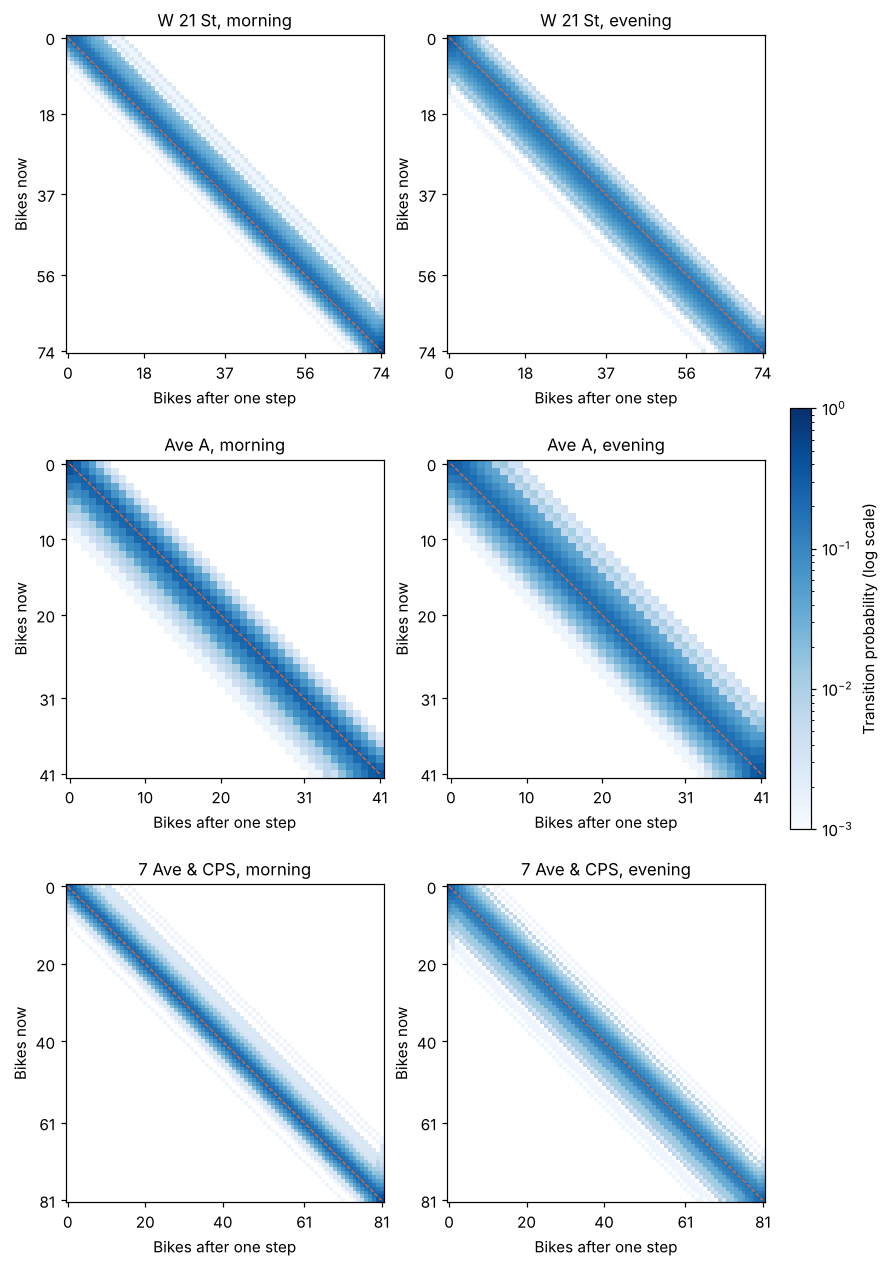

In [15]:
# appendix figure: full matrices on a log scale
fig, axes = plt.subplots(3, 2, figsize=(10, 14.2))
for r, (sid, st) in enumerate(STATIONS.items()):
    C = st["docks"]
    for c, block in enumerate(BLOCKS):
        P = P_all[(sid, block)]
        ax = axes[r, c]
        im = ax.imshow(np.where(P > 0, P, np.nan), cmap="Blues", norm=LogNorm(1e-3, 1), interpolation="nearest")
        ax.plot([0, C], [0, C], color="#eb6834", lw=0.8, ls="--")
        ax.set_title(f"{st['name']}, {block.lower()}")
        ax.set_xlabel("Bikes after one step")
        ax.set_ylabel("Bikes now")
        ticks = np.linspace(0, C, 5).round().astype(int)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
cbar = fig.colorbar(im, ax=axes, shrink=0.35, pad=0.03)
cbar.set_label("Transition probability (log scale)")
fig.savefig("figures/p1_matrices.png", dpi=250, bbox_inches="tight")

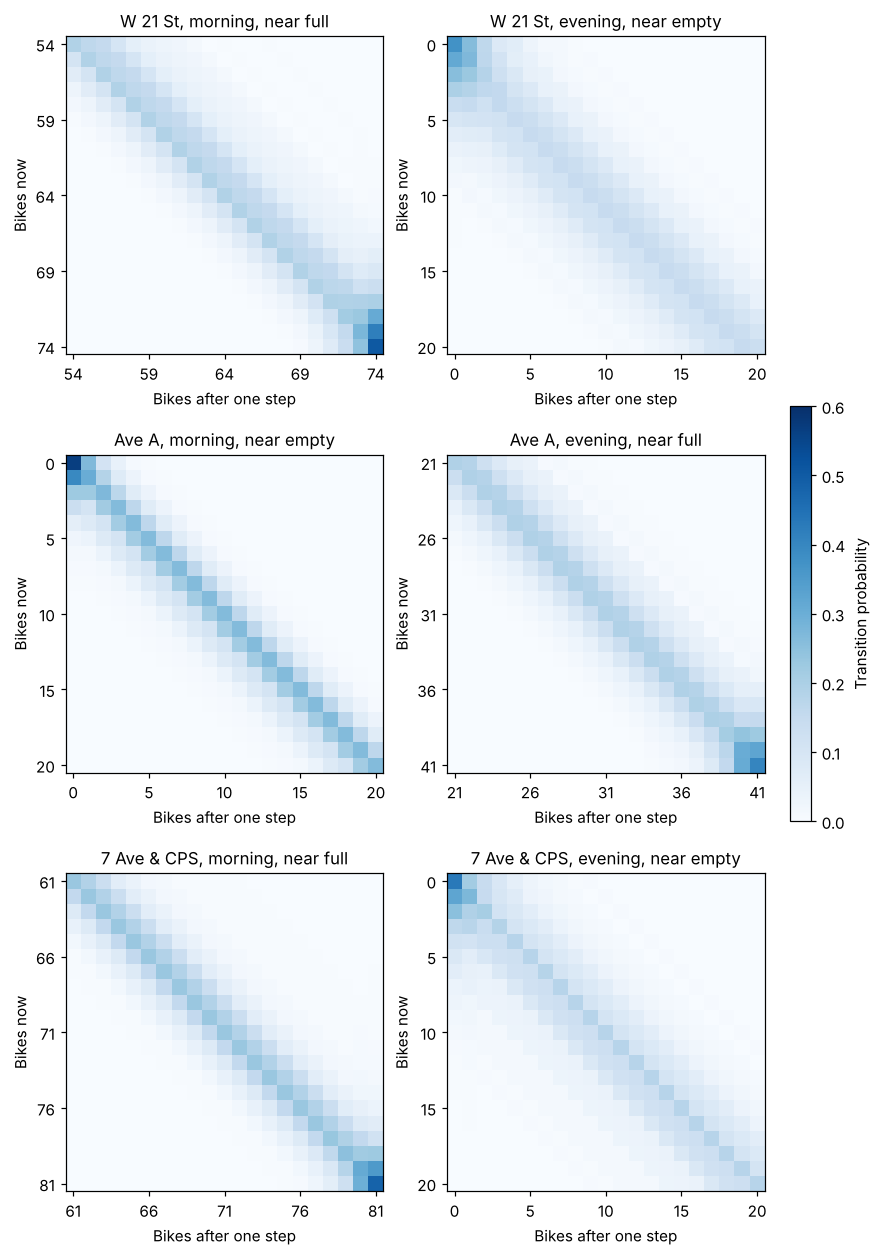

In [16]:
# appendix figure: zoom on the 21 states next to the edge each chain moves towards, linear scale
WIDTH = 21
fig, axes = plt.subplots(3, 2, figsize=(10, 14))
for r, (sid, st) in enumerate(STATIONS.items()):
    C = st["docks"]
    for c, block in enumerate(BLOCKS):
        edge = EDGE[block][sid]
        idx = np.arange(C - WIDTH + 1, C + 1) if edge == "full" else np.arange(WIDTH)
        ax = axes[r, c]
        im = ax.imshow(P_all[(sid, block)][np.ix_(idx, idx)], cmap="Blues", vmin=0, vmax=0.6, interpolation="nearest")
        ticks = np.arange(0, WIDTH, 5)
        ax.set_xticks(ticks)
        ax.set_xticklabels(idx[ticks])
        ax.set_yticks(ticks)
        ax.set_yticklabels(idx[ticks])
        ax.set_title(f"{st['name']}, {block.lower()}, near {edge}")
        ax.set_xlabel("Bikes after one step")
        ax.set_ylabel("Bikes now")
cbar = fig.colorbar(im, ax=axes, shrink=0.35, pad=0.03)
cbar.set_label("Transition probability")
fig.savefig("figures/p1_matrix_edges.png", dpi=250, bbox_inches="tight")

## 8. Stationary distributions (report Table 9)

Irreducible: every state can be reached from every other. Aperiodic: every state has a self-loop.
Hours to get close: steps until the distribution is within 0.05 of pi (total variation) from the worst starting state.

In [17]:
def is_irreducible(P):
    reach = (P > 0) | np.eye(len(P), dtype=bool)
    for _ in range(10):  # each squaring doubles the path length, 2^10 > number of states
        reach = (reach.astype(np.int64) @ reach.astype(np.int64)) > 0
    return reach.all()

def hours_to_mix(P, pi, tol=0.05, max_steps=20000):
    dist = np.eye(len(P))
    for n in range(1, max_steps + 1):
        dist = dist @ P
        if 0.5 * np.abs(dist - pi).sum(axis=1).max() < tol:
            return n * 5 / 60
    return np.inf

rows = []
for (sid, block), P in P_all.items():
    C = STATIONS[sid]["docks"]
    pi = pi_all[(sid, block)]
    rows.append({"station": STATIONS[sid]["name"], "block": block,
                 "irreducible": is_irreducible(P), "aperiodic": (np.diag(P) > 0).all(),
                 "long-run empty": pi[0], "long-run full": pi[C],
                 "long-run average bikes": pi @ np.arange(C + 1), "docks": C,
                 "hours to get close": hours_to_mix(P, pi)})
stationary_table = pd.DataFrame(rows)
stationary_table.round(3)

,station,block,irreducible,aperiodic,long-run empty,long-run full,long-run average bikes,docks,hours to get close
0,W 21 St,Morning,True,True,0.000,0.346,72.092,74,6.417
1,W 21 St,Evening,True,True,0.206,0.000,3.872,74,7.917
2,Ave A,Morning,True,True,0.289,0.000,2.671,41,9.833
3,Ave A,Evening,True,True,0.000,0.176,36.410,41,8.250
4,7 Ave & CPS,Morning,True,True,0.000,0.210,77.066,81,17.500
5,7 Ave & CPS,Evening,True,True,0.155,0.000,7.482,81,14.083


## 9. What happens within one block (report Table 10)

Start half full, push the distribution forward 36 steps, and solve h = 1 + Q h for the expected time to reach the edge.

In [18]:
def hitting_time(P, target):
    others = [s for s in range(len(P)) if s != target]
    Q = P[np.ix_(others, others)]
    h = np.linalg.solve(np.eye(len(others)) - Q, np.ones(len(others)))
    out = np.zeros(len(P))
    out[others] = h
    return out

rows = []
for (sid, block), P in P_all.items():
    C = STATIONS[sid]["docks"]
    start = C // 2
    edge_state = C if EDGE[block][sid] == "full" else 0

    dist = np.eye(C + 1)[start]
    share_at_edge = 0
    for _ in range(STEPS_PER_BLOCK):
        dist = dist @ P
        share_at_edge += dist[edge_state] / STEPS_PER_BLOCK

    rows.append({"station": STATIONS[sid]["name"], "block": block, "start": start,
                 "average bikes at the end": dist @ np.arange(C + 1),
                 "empty at the end": dist[0], "full at the end": dist[C],
                 "share of block at the edge": share_at_edge,
                 "hours to reach the edge": hitting_time(P, edge_state)[start] * 5 / 60})
block_table = pd.DataFrame(rows)
block_table.round(3)

,station,block,start,average bikes at the end,empty at the end,full at the end,share of block at the edge,hours to reach the edge
0,W 21 St,Morning,37,70.340,0.000,0.288,0.106,2.521
1,W 21 St,Evening,37,8.002,0.150,0.000,0.057,3.103
2,Ave A,Morning,20,6.244,0.184,0.000,0.071,3.511
3,Ave A,Evening,20,33.436,0.001,0.132,0.063,3.392
4,7 Ave & CPS,Morning,40,59.225,0.000,0.031,0.007,6.542
5,7 Ave & CPS,Evening,40,19.290,0.069,0.000,0.024,5.396


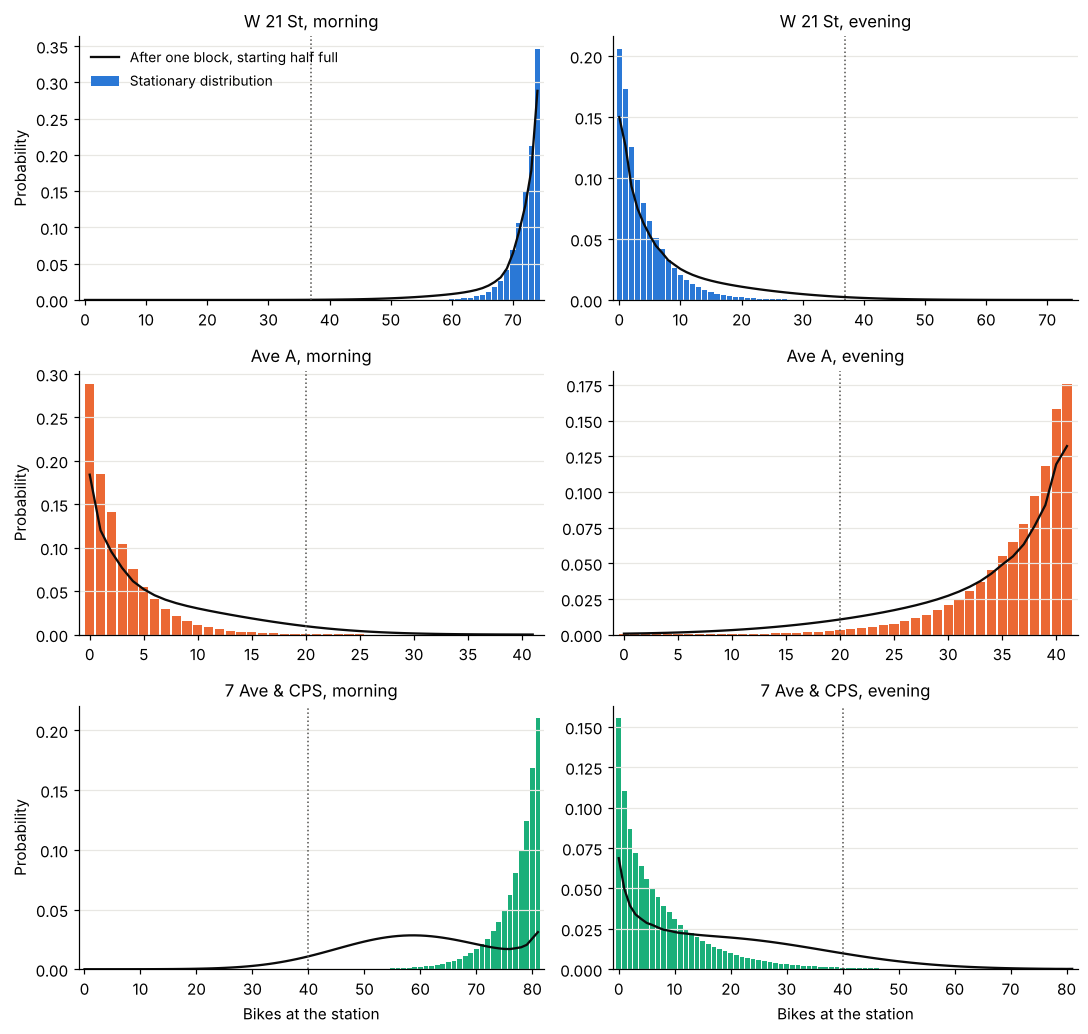

In [19]:
# Figure 6: stationary distribution (bars) and distribution after one block starting half full (line)
fig, axes = plt.subplots(3, 2, figsize=(10, 9.5))
for r, (sid, st) in enumerate(STATIONS.items()):
    C = st["docks"]
    for c, block in enumerate(BLOCKS):
        P = P_all[(sid, block)]
        start = C // 2
        after_block = np.linalg.matrix_power(P, STEPS_PER_BLOCK)[start]
        ax = axes[r, c]
        ax.bar(np.arange(C + 1), pi_all[(sid, block)], width=0.85, color=st["color"], label="Stationary distribution")
        ax.plot(np.arange(C + 1), after_block, color="#0b0b0b", lw=1.5, label="After one block, starting half full")
        ax.axvline(start, color="#52514e", lw=1, ls=":")
        ax.set_title(f"{st['name']}, {block.lower()}")
        ax.set_xlim(-1, C + 1)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e8e7e3")
        if r == 0 and c == 0:
            ax.legend(frameon=False, fontsize=9, loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("Bikes at the station")
for ax in axes[:, 0]:
    ax.set_ylabel("Probability")
fig.tight_layout()
fig.savefig("figures/p1_stationary.png", dpi=250, bbox_inches="tight")

## 10. Bikes moved by staff

The data only has rides, not vans. But a station can never swing by more bikes than it has docks,
so a day where the running count of arrivals minus departures swings by more than C shows that staff moved bikes.

In [20]:
rows = []
for sid, st in STATIONS.items():
    e = events[events.station == sid]
    swing = e.groupby(e.time.dt.date).event.apply(lambda x: np.ptp(np.concatenate([[0], x.cumsum().values])))
    rows.append({"station": st["name"], "docks": st["docks"], "median daily swing": swing.median(),
                 "largest swing": swing.max(), "days with swing > docks": int((swing > st["docks"]).sum())})
pd.DataFrame(rows)

,station,docks,median daily swing,largest swing,days with swing > docks
0,W 21 St,74,69.0,73,0
1,Ave A,41,38.0,53,4
2,7 Ave & CPS,81,46.0,79,0
